<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Equações Diferenciais em Python — Modelagem e Simulação de Sistemas Dinâmicos.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Em um processo industrial, temperatura, concentração, pressão e nível podem mudar ao longo do tempo. Para compreender essas mudanças, a Engenharia recorre a modelos dinâmicos expressos por equações diferenciais. O objetivo deste notebook é **construir esses modelos a partir dos fenômenos físicos**, resolver exemplos simples manualmente, programar os métodos numéricos e interpretar os resultados.

Os dados dos exemplos são didáticos. As hipóteses de cada modelo precisam ser verificadas antes de qualquer aplicação experimental ou industrial.

**Objetivos de aprendizagem:** formular equações diferenciais ordinárias (EDOs), estabelecer condições iniciais, implementar Euler e RK4, avaliar erros e convergência, simular balanços de massa e energia e compreender o uso de um integrador científico.

**Sumário**

1. [O que caracteriza um sistema dinâmico?](#secao-1)
2. [Das leis de conservação às equações diferenciais](#secao-2)
3. [Condição inicial, parâmetros e unidades](#secao-3)
4. [Solução analítica de um modelo de primeira ordem](#secao-4)
5. [Discretização temporal e método de Euler](#secao-5)
6. [Implementação de Euler sem bibliotecas de integração](#secao-6)
7. [Comparação com a solução analítica e erro](#secao-7)
8. [Influência do passo e convergência](#secao-8)
9. [Método de Runge–Kutta de quarta ordem (RK4)](#secao-9)
10. [Comparação entre Euler e RK4](#secao-10)
11. [Tanque com entrada e saída variáveis](#secao-11)
12. [Mistura em tanque perfeitamente agitado](#secao-12)
13. [Transferência de Calor: resfriamento transiente](#secao-13)
14. [Controle de Processos: resposta a um degrau](#secao-14)
15. [Reator químico: reação de primeira ordem](#secao-15)
16. [Sistemas de equações diferenciais acopladas](#secao-16)
17. [Simulação com scipy.integrate.solve_ivp](#secao-17)
18. [Validação física e boas práticas](#secao-18)
19. [Exercícios de consolidação](#secao-19)
20. [Conclusões](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O que caracteriza um sistema dinâmico?</div>

Um modelo estacionário descreve uma condição na qual as variáveis de estado não variam com o tempo. Um **modelo dinâmico** descreve como essas variáveis evoluem em resposta a entradas, perturbações e condições iniciais.

Por exemplo, em um tanque, a diferença entre as vazões de entrada e saída provoca acúmulo ou redução do volume. Em um sistema térmico, a troca de calor modifica a temperatura. Uma equação diferencial representa quantitativamente a taxa dessas mudanças.

A presença de uma derivada temporal não significa, por si só, que um modelo é adequado: ele precisa respeitar os balanços de conservação e as hipóteses físicas.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Das leis de conservação às equações diferenciais</div>

A construção do modelo começa com a lei de conservação:

$$\boxed{\text{Acúmulo}=\text{Entrada}-\text{Saída}+\text{Geração}-\text{Consumo}.}$$

Para um tanque de líquido incompressível, com densidade constante e sem reação, o balanço global fornece

$$\frac{dV}{dt}=Q_{in}-Q_{out}.$$

Se as vazões são constantes, a derivada também é constante. Se a vazão de saída depende do nível, o problema passa a exigir uma equação diferencial cuja solução pode ser não linear. A definição da fronteira do sistema, das hipóteses e das unidades precede a programação.

<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Condição inicial, parâmetros e unidades</div>

Uma EDO de primeira ordem pode ser escrita como

$$\frac{dy}{dt}=f(t,y,\boldsymbol{p}),\qquad y(t_0)=y_0,$$

em que $y$ é a variável de estado, $\boldsymbol{p}$ representa os parâmetros e $y_0$ é a **condição inicial**. Sem uma condição inicial, a equação geralmente não determina uma trajetória única.

No balanço de volume, $V$ está em litros, $t$ em minutos e $Q$ em L/min. A igualdade $dV/dt=Q_{in}-Q_{out}$ é dimensionalmente coerente. Essa verificação simples é indispensável em qualquer simulação.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. Solução analítica de um modelo de primeira ordem</div>

**Problema de Engenharia — Acúmulo em tanque.** Considere $V_0=50$ L, $Q_{in}=5$ L/min e $Q_{out}=4$ L/min. O modelo é

$$\frac{dV}{dt}=5-4=1\ \mathrm{L/min},\qquad V(0)=50\ \mathrm{L}.$$

Integrando de $0$ a $t$:

$$V(t)=50+t.$$

Para $t=10$ min, o cálculo manual fornece $V(10)=60$ L. Essa solução é válida apenas enquanto o tanque não transborda, não esvazia e as vazões permanecem constantes.

Volume aos 10 min: 60.0 L


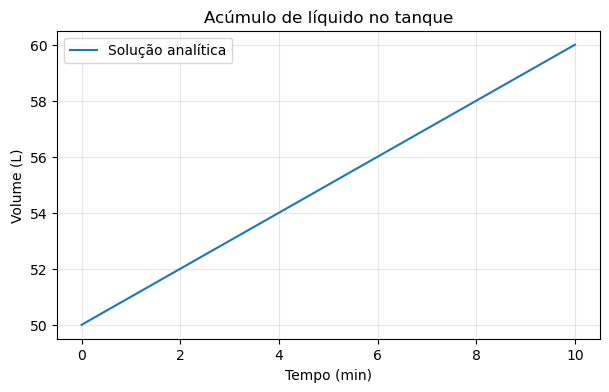

In [15]:
import numpy as np
import matplotlib.pyplot as plt

tempo = np.linspace(0.0, 10.0, 101)
V0, Qin, Qout = 50.0, 5.0, 4.0
volume_exato = V0 + (Qin-Qout)*tempo
print(f"Volume aos 10 min: {volume_exato[-1]:.1f} L")
plt.figure(figsize=(7,4))
plt.plot(tempo, volume_exato, label="Solução analítica")
plt.xlabel("Tempo (min)"); plt.ylabel("Volume (L)")
plt.title("Acúmulo de líquido no tanque")
plt.grid(alpha=0.3); plt.legend(); plt.show()

**Interpretação:** o volume cresce linearmente porque a diferença entre as vazões é constante. O gráfico mostra a consequência do balanço de massa, e não apenas uma tendência estatística.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Discretização temporal e método de Euler</div>

Quando a solução analítica não é conhecida, discretizamos o tempo. No **método de Euler explícito**, a derivada é aproximada por

$$\frac{dy}{dt}\bigg|_{t_n}\approx\frac{y_{n+1}-y_n}{\Delta t}.$$

Logo,

$$\boxed{y_{n+1}=y_n+\Delta t\,f(t_n,y_n).}$$

Para o tanque, com $\Delta t=1$ min, $V_1=50+1(5-4)=51$ L. No instante seguinte, $V_2=52$ L. A implementação repete exatamente essa operação, tornando explícito o algoritmo.

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Implementação de Euler sem bibliotecas de integração</div>

Primeiro programaremos um integrador Euler genérico. O argumento `f` representa o lado direito da equação diferencial; o integrador não precisa conhecer o significado físico de $y$. Essa separação permite reutilizar o mesmo algoritmo em problemas de Engenharia diferentes.

In [16]:
def euler(f, t0, tf, y0, passo):
    if passo <= 0 or tf <= t0:
        raise ValueError("O passo deve ser positivo e tf deve exceder t0.")
    n = int(np.ceil((tf-t0)/passo))
    tempos = np.linspace(t0, tf, n+1)
    h = tempos[1]-tempos[0]
    valores = np.empty(n+1, dtype=float)
    valores[0] = float(y0)
    for k in range(n):
        valores[k+1] = valores[k]+h*f(tempos[k], valores[k])
        if not np.isfinite(valores[k+1]):
            raise ValueError("Resultado não finito na integração.")
    return tempos, valores

def dVdt(t, V):
    return Qin-Qout

t_e, V_e = euler(dVdt, 0.0, 10.0, V0, 1.0)
print("Volumes por Euler (L):", V_e)
print("Erro máximo:", np.max(np.abs(V_e-(V0+(Qin-Qout)*t_e))), "L")

Volumes por Euler (L): [50. 51. 52. 53. 54. 55. 56. 57. 58. 59. 60.]
Erro máximo: 0.0 L


**Interpretação:** para uma derivada constante, Euler reproduz a solução analítica nos instantes calculados (salvo possíveis arredondamentos). Para derivadas que dependem do estado, o erro de discretização normalmente será diferente de zero.

<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Comparação com a solução analítica e erro</div>

**Problema de Engenharia — Resfriamento de primeira ordem.** Para um corpo com temperatura uniforme e propriedades constantes, considere

$$\frac{dT}{dt}=-k(T-T_a),\qquad T(0)=T_0.$$

A solução analítica é

$$T(t)=T_a+(T_0-T_a)e^{-kt}.$$

Com $T_0=80$ °C, $T_a=20$ °C e $k=0{,}1$ $min^{-1}$, temos $T(10)=20+60e^{-1}\approx42{,}07$ °C. A primeira iteração de Euler com passo de 1 min fornece $T_1=80-0{,}1(80-20)=74$ °C. A diferença entre a solução numérica e a analítica permite avaliar o erro.

Euler em 10 min: 40.9207 °C
Exata em 10 min: 42.0728 °C
Erro absoluto final: 1.1521 °C


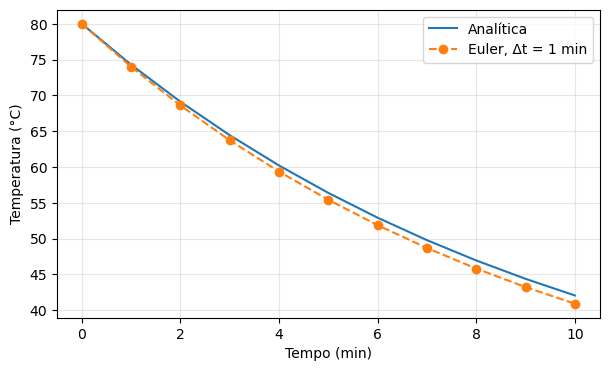

In [17]:
T0, Ta, k = 80.0, 20.0, 0.1
def dTdt(t, T):
    return -k*(T-Ta)

t_e, T_e = euler(dTdt, 0.0, 10.0, T0, 1.0)
T_exata = Ta+(T0-Ta)*np.exp(-k*t_e)
print(f"Euler em 10 min: {T_e[-1]:.4f} °C")
print(f"Exata em 10 min: {T_exata[-1]:.4f} °C")
print(f"Erro absoluto final: {abs(T_e[-1]-T_exata[-1]):.4f} °C")
plt.figure(figsize=(7,4))
plt.plot(t_e,T_exata,"-",label="Analítica")
plt.plot(t_e,T_e,"o--",label="Euler, Δt = 1 min")
plt.xlabel("Tempo (min)");plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3);plt.legend();plt.show()

<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Influência do passo e convergência</div>

O passo $\Delta t$ controla a resolução temporal. Para Euler explícito, o erro global costuma ser de primeira ordem, isto é, proporcional a $\Delta t$ sob hipóteses de regularidade e estabilidade. Isso significa que reduzir o passo tende a melhorar a aproximação, mas não corrige um modelo físico incorreto.

Para $dT/dt=-k(T-T_a)$, a estabilidade linear de Euler exige $|1-k\Delta t|<1$, ou $0<k\Delta t<2$. Para evitar oscilações artificiais, é conveniente manter $k\Delta t\leq1$.

In [18]:
passos = [2.0, 1.0, 0.5, 0.25]
T_final_exata = Ta+(T0-Ta)*np.exp(-k*10.0)
for h in passos:
    ts, ys = euler(dTdt, 0.0, 10.0, T0, h)
    print(f"Δt={h:4.2f} min | T(10)={ys[-1]:.5f} °C | erro={abs(ys[-1]-T_final_exata):.5f} °C")

Δt=2.00 min | T(10)=39.66080 °C | erro=2.41197 °C
Δt=1.00 min | T(10)=40.92071 °C | erro=1.15206 °C
Δt=0.50 min | T(10)=41.50916 °C | erro=0.56361 °C
Δt=0.25 min | T(10)=41.79395 °C | erro=0.27882 °C


**Interpretação:** a redução progressiva do erro com a diminuição do passo indica convergência para a solução analítica neste exemplo. Em modelos mais complexos, devemos também avaliar conservação, estabilidade e escalas temporais.

<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Método de Runge–Kutta de quarta ordem (RK4)</div>

O método de **Runge–Kutta de quarta ordem (RK4)** melhora a estimativa da evolução dentro de cada intervalo. Para $y\prime=f(t,y)$ e passo $h$, calculamos

$$\begin{aligned}k_1&=f(t_n,y_n),\\k_2&=f(t_n+h/2,y_n+hk_1/2),\\k_3&=f(t_n+h/2,y_n+hk_2/2),\\k_4&=f(t_n+h,y_n+hk_3),\end{aligned}$$

$$\boxed{y_{n+1}=y_n+\frac{h}{6}(k_1+2k_2+2k_3+k_4).}$$

Para o resfriamento, $T_0=80$ °C, $T_a=20$ °C, $k=0{,}1$ min$^{-1}$ e $h=1$ min, as inclinações são $k_1=-6$, $k_2=-5{,}7$, $k_3=-5{,}715$ e $k_4=-5{,}4285$ °C/min. Portanto, $T_1\approx74{,}29025$ °C. O método exige quatro avaliações da função por passo.

In [19]:
def rk4(f, t0, tf, y0, passo):
    if passo <= 0 or tf <= t0:
        raise ValueError("O passo deve ser positivo e tf deve exceder t0.")
    n = int(np.ceil((tf-t0)/passo))
    tempos = np.linspace(t0, tf, n+1)
    h = tempos[1]-tempos[0]
    y = np.asarray(y0, dtype=float)
    valores = np.empty((n+1,)+y.shape, dtype=float)
    valores[0] = y
    for j in range(n):
        t = tempos[j]
        k1 = np.asarray(f(t,y),dtype=float)
        k2 = np.asarray(f(t+h/2,y+h*k1/2),dtype=float)
        k3 = np.asarray(f(t+h/2,y+h*k2/2),dtype=float)
        k4 = np.asarray(f(t+h,y+h*k3),dtype=float)
        y = y+h*(k1+2*k2+2*k3+k4)/6
        if not np.isfinite(y).all():
            raise ValueError("Resultado não finito na integração.")
        valores[j+1] = y
    return tempos, valores

t_rk, T_rk = rk4(dTdt,0.0,10.0,T0,1.0)
print(f"Primeiro passo RK4: {T_rk[1]:.5f} °C")
print(f"Temperatura final RK4: {T_rk[-1]:.5f} °C")

Primeiro passo RK4: 74.29025 °C
Temperatura final RK4: 42.07279 °C


<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Comparação entre Euler e RK4</div>

Vamos comparar Euler e RK4 com o mesmo passo e a mesma equação diferencial. A comparação só é válida se utilizarmos a mesma condição inicial e os mesmos parâmetros.

RK4 apresenta erro global de quarta ordem em problemas suficientemente regulares, mas isso não garante estabilidade para qualquer passo nem torna o modelo físico mais fiel. Métodos de ordem maior podem ser inadequados para problemas rígidos (*stiff*).

Erro final Euler: 1.152060 °C
Erro final RK4:   0.000020 °C


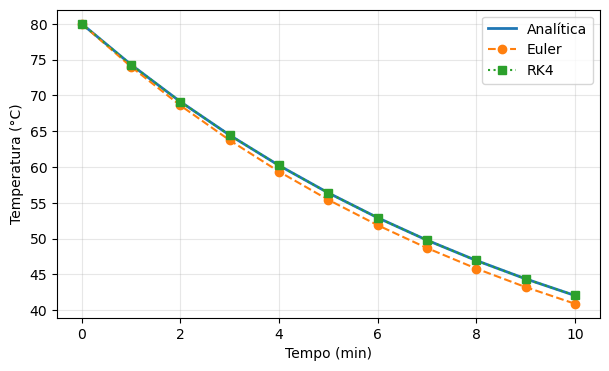

In [20]:
T_exata_rk = Ta+(T0-Ta)*np.exp(-k*t_rk)
print(f"Erro final Euler: {abs(T_e[-1]-T_final_exata):.6f} °C")
print(f"Erro final RK4:   {abs(T_rk[-1]-T_final_exata):.6f} °C")
plt.figure(figsize=(7,4))
plt.plot(t_rk,T_exata_rk,label="Analítica",linewidth=2)
plt.plot(t_e,T_e,"o--",label="Euler")
plt.plot(t_rk,T_rk,"s:",label="RK4")
plt.xlabel("Tempo (min)");plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3);plt.legend();plt.show()

<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Tanque com entrada e saída variáveis</div>

**Problema de Engenharia — Esvaziamento dependente do volume.** Considere um tanque com $Q_{in}=5$ L/min e saída proporcional ao volume, $Q_{out}=aV$, com $a=0{,}08$ min$^{-1}$. O balanço é

$$\frac{dV}{dt}=5-0{,}08V,\qquad V(0)=50\ \mathrm{L}.$$

O volume de equilíbrio satisfaz $0=5-0{,}08V_{eq}$, portanto $V_{eq}=62{,}5$ L. Inicialmente, $dV/dt=5-0{,}08(50)=1$ L/min. A solução analítica, usada aqui para conferir a simulação, é

$$V(t)=V_{eq}+(V_0-V_{eq})e^{-at}.$$

A proporcionalidade entre saída e volume é uma hipótese didática; um escoamento gravitacional real pode depender da raiz quadrada da altura.

Volume de equilíbrio: 62.50 L
Volume em 30 min: 61.366 L
Erro máximo: 1.014e-07 L


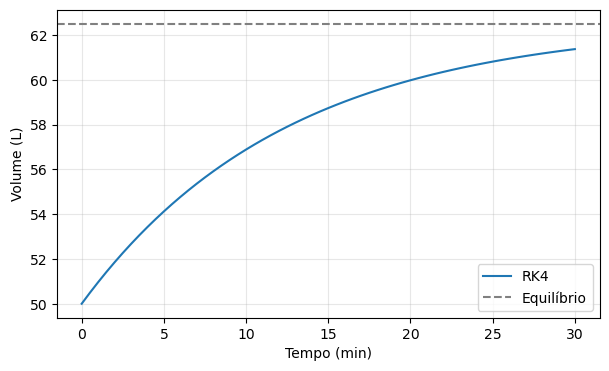

In [21]:
a_saida=0.08
V_eq=Qin/a_saida
def tanque_variavel(t,V):
    return Qin-a_saida*V

t_v,V_v = rk4(tanque_variavel,0.0,30.0,50.0,0.5)
V_v_exata=V_eq+(50.0-V_eq)*np.exp(-a_saida*t_v)
print(f"Volume de equilíbrio: {V_eq:.2f} L")
print(f"Volume em 30 min: {V_v[-1]:.3f} L")
print(f"Erro máximo: {np.max(np.abs(V_v-V_v_exata)):.3e} L")
plt.figure(figsize=(7,4));plt.plot(t_v,V_v,label="RK4")
plt.axhline(V_eq,color="gray",linestyle="--",label="Equilíbrio")
plt.xlabel("Tempo (min)");plt.ylabel("Volume (L)")
plt.grid(alpha=0.3);plt.legend();plt.show()

**Interpretação:** o volume tende ao equilíbrio porque a saída aumenta quando o volume cresce. A existência e a localização desse equilíbrio decorrem do balanço e da hipótese sobre a vazão de saída.

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Mistura em tanque perfeitamente agitado</div>

**Problema de Engenharia — Mistura perfeitamente agitada.** Considere um tanque com volume constante $V=100$ L, entrada e saída iguais a $Q=10$ L/min, concentração de alimentação $C_{in}=8$ g/L e concentração inicial $C(0)=2$ g/L. Assumindo mistura perfeita, densidade constante e ausência de reação:

$$\frac{d(VC)}{dt}=QC_{in}-QC.$$

Como $V$ é constante,

$$\frac{dC}{dt}=\frac{Q}{V}(C_{in}-C).$$

No instante inicial, $dC/dt=(10/100)(8-2)=0{,}6$ g/(L·min). A solução analítica é $C(t)=C_{in}+(C_0-C_{in})e^{-(Q/V)t}$.

Concentração em 10 min: 5.7927 g/L


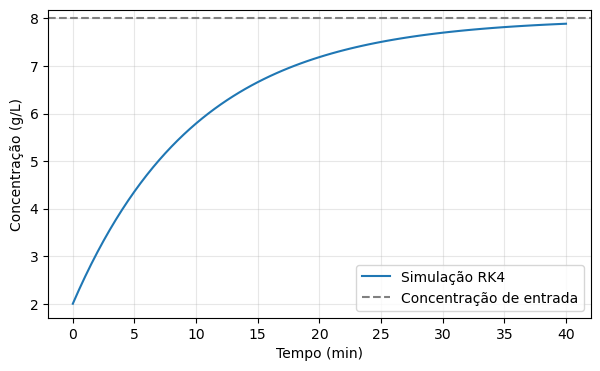

In [22]:
V_mistura=100.0; Q_mistura=10.0; Cin=8.0; C0=2.0
def dCdt(t,C):
    return (Q_mistura/V_mistura)*(Cin-C)

t_m,C_m = rk4(dCdt,0.0,40.0,C0,0.5)
C_analitica=Cin+(C0-Cin)*np.exp(-(Q_mistura/V_mistura)*t_m)
print(f"Concentração em 10 min: {np.interp(10,t_m,C_m):.4f} g/L")
plt.figure(figsize=(7,4));plt.plot(t_m,C_m,label="Simulação RK4")
plt.axhline(Cin,color="gray",linestyle="--",label="Concentração de entrada")
plt.xlabel("Tempo (min)");plt.ylabel("Concentração (g/L)")
plt.grid(alpha=0.3);plt.legend();plt.show()

**Interpretação:** a concentração aproxima-se gradualmente da concentração de alimentação. O tempo característico $V/Q=10$ min expressa a escala temporal da mistura no modelo.

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Transferência de Calor: resfriamento transiente</div>

**Problema de Engenharia — Transferência de Calor transiente.** Um corpo de capacidade térmica $mc_p$ troca calor por convecção com o ambiente. Sob a hipótese de temperatura interna uniforme,

$$mc_p\frac{dT}{dt}=-hA(T-T_a).$$

Definindo $k=hA/(mc_p)$, recuperamos o modelo de resfriamento de primeira ordem. Considere $m=2$ kg, $c_p=900$ J/(kg·K), $h=15$ W/(m²·K) e $A=0{,}5$ m². Então $k=7{,}5/1800\approx0{,}004167$ s$^{-1}$.

A hipótese de temperatura uniforme precisa ser justificada, por exemplo, pela avaliação do número de Biot em uma situação física concreta.

Constante térmica: 240.0 s
Temperatura em 600 s: 31.16 °C


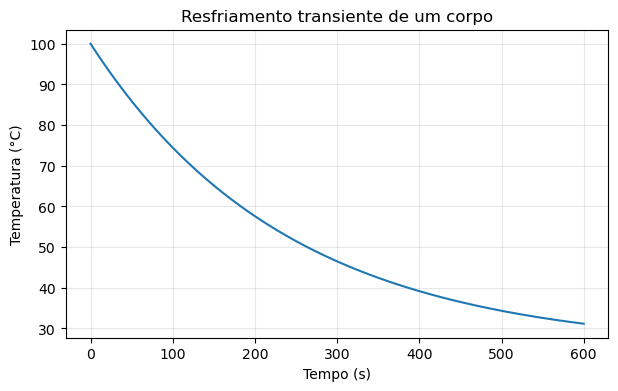

In [23]:
m_corpo=2.0; cp=900.0; h_conv=15.0; A_troca=0.5
k_seg=h_conv*A_troca/(m_corpo*cp)
def dT_calor(t,T):
    return -k_seg*(T-25.0)

t_cal,T_cal = rk4(dT_calor,0.0,600.0,100.0,5.0)
print(f"Constante térmica: {1/k_seg:.1f} s")
print(f"Temperatura em 600 s: {T_cal[-1]:.2f} °C")
plt.figure(figsize=(7,4));plt.plot(t_cal,T_cal)
plt.xlabel("Tempo (s)");plt.ylabel("Temperatura (°C)")
plt.title("Resfriamento transiente de um corpo")
plt.grid(alpha=0.3);plt.show()

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Controle de Processos: resposta a um degrau</div>

**Problema de Engenharia — Resposta dinâmica a um degrau.** Um processo térmico linear de primeira ordem pode ser representado por

$$\tau\frac{dT}{dt}+T=T_{SP},$$

onde $T_{SP}$ é a referência e $\tau$ é a constante de tempo. Esta equação descreve aqui uma resposta idealizada do processo, **não a implementação de um controlador PID**.

Se $T(0)=30$ °C, $T_{SP}=70$ °C e $\tau=5$ min, a inclinação inicial é $(70-30)/5=8$ °C/min. A solução é

$$T(t)=T_{SP}+(T_0-T_{SP})e^{-t/\tau}.$$

O erro de controle é $e(t)=T_{SP}-T(t)$, e tende a zero nesse modelo sem perturbações.

T(5 min): 55.285 °C
Erro em 5 min: 14.715 °C


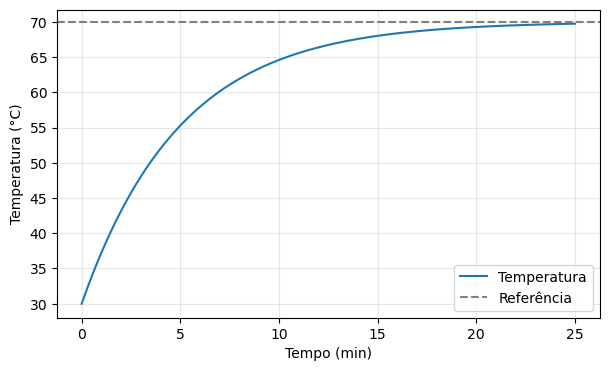

In [24]:
Tsp=70.0; tau=5.0; T_inicial=30.0
def resposta_degrau(t,T):
    return (Tsp-T)/tau

t_p,T_p = rk4(resposta_degrau,0.0,25.0,T_inicial,0.25)
erro=Tsp-T_p
print(f"T(5 min): {np.interp(5,t_p,T_p):.3f} °C")
print(f"Erro em 5 min: {np.interp(5,t_p,erro):.3f} °C")
plt.figure(figsize=(7,4));plt.plot(t_p,T_p,label="Temperatura")
plt.axhline(Tsp,linestyle="--",color="gray",label="Referência")
plt.xlabel("Tempo (min)");plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3);plt.legend();plt.show()

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Reator químico: reação de primeira ordem</div>

**Problema de Engenharia — Reação de primeira ordem.** Em um reator batelada ideal, isotérmico, de volume constante, com reação irreversível $A\to B$ e cinética de primeira ordem,

$$\frac{dC_A}{dt}=-k_rC_A.$$

Para $C_A(0)=2$ mol/L e $k_r=0{,}15$ min$^{-1}$, a taxa inicial é $-0{,}30$ mol/(L·min). A solução analítica é $C_A(t)=C_{A0}e^{-k_rt}$ e a conversão é $X_A=1-C_A/C_{A0}$.

O modelo pressupõe mistura perfeita e temperatura constante; em reações exotérmicas reais, a temperatura pode modificar significativamente a cinética.

Concentração final: 0.0996 mol/L
Conversão final: 95.02%


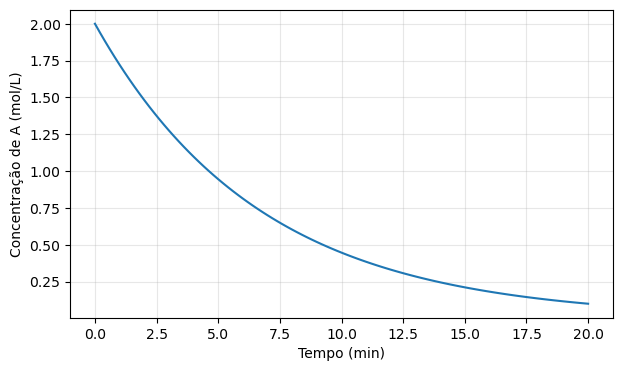

In [25]:
CA0=2.0; kr=0.15
def reacao_primeira_ordem(t,CA):
    return -kr*CA

t_r,CA = rk4(reacao_primeira_ordem,0.0,20.0,CA0,0.2)
conversao=1-CA/CA0
print(f"Concentração final: {CA[-1]:.4f} mol/L")
print(f"Conversão final: {100*conversao[-1]:.2f}%")
plt.figure(figsize=(7,4));plt.plot(t_r,CA)
plt.xlabel("Tempo (min)");plt.ylabel("Concentração de A (mol/L)")
plt.grid(alpha=0.3);plt.show()

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Sistemas de equações diferenciais acopladas</div>

**Problema de Engenharia — Dois tanques perfeitamente misturados.** Considere dois tanques de volume constante, $V_1=V_2=100$ L, conectados em série, com vazão $Q=10$ L/min. A alimentação do primeiro tem concentração $C_{in}=8$ g/L. O efluente do primeiro alimenta o segundo.

Os balanços de massa são

$$\frac{dC_1}{dt}=\frac{Q}{V_1}(C_{in}-C_1),\qquad\frac{dC_2}{dt}=\frac{Q}{V_2}(C_1-C_2).$$

Com $C_1(0)=C_2(0)=0$, as inclinações iniciais são $dC_1/dt=0{,}8$ e $dC_2/dt=0$ g/(L·min). O segundo tanque responde mais lentamente porque sua entrada depende da concentração do primeiro. Agora o estado é um **vetor** $\mathbf y=[C_1,C_2]^T$.

Concentrações finais (g/L): [7.98016998 7.86118987]


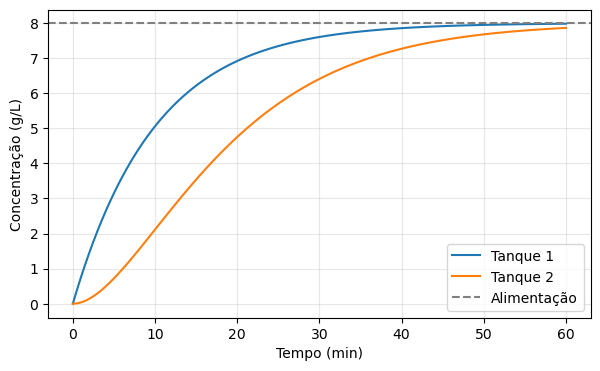

In [26]:
V1=100.0; V2=100.0; Q=10.0; Cin=8.0
def dois_tanques(t,y):
    C1,C2=y
    return np.array([Q/V1*(Cin-C1),Q/V2*(C1-C2)])

t_2,C_2 = rk4(dois_tanques,0.0,60.0,np.array([0.0,0.0]),0.5)
print("Concentrações finais (g/L):",C_2[-1])
plt.figure(figsize=(7,4))
plt.plot(t_2,C_2[:,0],label="Tanque 1")
plt.plot(t_2,C_2[:,1],label="Tanque 2")
plt.axhline(Cin,color="gray",linestyle="--",label="Alimentação")
plt.xlabel("Tempo (min)");plt.ylabel("Concentração (g/L)")
plt.grid(alpha=0.3);plt.legend();plt.show()

**Interpretação:** a concentração do segundo tanque apresenta atraso em relação à do primeiro. A simulação traduz a interação física entre os balanços de massa, não apenas o acoplamento matemático.

<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Simulação com scipy.integrate.solve_ivp</div>

Após implementar os métodos manualmente, podemos recorrer a um integrador científico. A função `scipy.integrate.solve_ivp` permite resolver problemas de valor inicial, escolher métodos de integração e controlar tolerâncias. A biblioteca SciPy pode ser instalada pelo terminal com `python -m pip install scipy`.

Para o modelo dos dois tanques, compararemos o resultado do `solve_ivp` com nosso RK4. A tolerância relativa `rtol` e a absoluta `atol` controlam o erro local estimado pelo integrador; não representam incertezas dos parâmetros ou dos instrumentos.

In [27]:
from scipy.integrate import solve_ivp

sol = solve_ivp(dois_tanques,(0.0,60.0),[0.0,0.0],
                t_eval=t_2,rtol=1e-9,atol=1e-11)
if not sol.success:
    raise RuntimeError(sol.message)
print("Concentrações finais (solve_ivp):",sol.y[:,-1])
print("Diferença máxima para RK4:",np.max(np.abs(sol.y.T-C_2)),"g/L")

Concentrações finais (solve_ivp): [7.98016998 7.86118988]
Diferença máxima para RK4: 5.064818977551511e-07 g/L


<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Validação física e boas práticas</div>

**Verificações indispensáveis.** Uma simulação confiável deve respeitar dimensões e unidades, condições iniciais, limites físicos e balanços de conservação. O resultado numérico precisa ser examinado quanto à convergência com o passo e à sensibilidade aos parâmetros.

Para concentrações não negativas, valores negativos significativos são incompatíveis com o modelo físico apresentado. Em um tanque real, volume negativo ou superior à capacidade nominal também exige revisão do modelo ou das condições de operação.

**Distinguir erros:** erro de discretização é diferente de erro de modelagem, erro de medição e incerteza dos parâmetros. Refinar o passo não elimina as outras fontes de erro.

In [28]:
assert np.all(C_2 >= -1e-10), "Concentração negativa relevante."
assert np.all(C_2 <= Cin+1e-10), "Concentração acima da alimentação."
assert np.all(np.diff(C_2[:,0]) >= -1e-10), "Tanque 1 não monotônico."
assert np.all(np.diff(C_2[:,1]) >= -1e-10), "Tanque 2 não monotônico."
print("Verificações físicas do modelo de dois tanques: aprovadas.")

Verificações físicas do modelo de dois tanques: aprovadas.


<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Exercícios de consolidação</div>

**Exercício 1 — Balanço de volume.** Um tanque contém inicialmente 40 L e recebe 6 L/min, descarregando 4,5 L/min. Obtenha a solução analítica, calcule manualmente $V(4)$ e simule com Euler.

**Exercício 2 — Passo temporal.** Para $dT/dt=-0{,}2(T-25)$ e $T(0)=75$ °C, compare Euler com passos de 1; 0,5 e 0,25 min até 5 min. Compare com a solução analítica.

**Exercício 3 — RK4.** Calcule manualmente as quatro inclinações de RK4 para a primeira iteração de $dy/dt=-0{,}1y$, $y(0)=10$ e $h=1$. Confirme em Python.

**Exercício 4 — Mistura.** Para um tanque com $V=80$ L, $Q=8$ L/min, $C_{in}=5$ g/L e $C(0)=1$ g/L, formule a EDO, calcule a inclinação inicial e simule até 30 min.

**Exercício 5 — Transferência de Calor.** Considere $m=1{,}5$ kg, $c_p=850$ J/(kg·K), $h=12$ W/(m²·K), $A=0{,}4$ m² e $T_a=25$ °C. Determine a constante de tempo e simule o resfriamento de 90 °C durante 15 min, utilizando segundos como unidade de tempo.

**Exercício 6 — Controle de Processos.** Simule a resposta a degrau de um processo de primeira ordem com $\tau=4$ min, $T(0)=35$ °C e $T_{SP}=65$ °C. Determine o erro após uma constante de tempo.

**Exercício 7 — Reator batelada.** Para $k_r=0{,}12$ min$^{-1}$ e $C_A(0)=1{,}5$ mol/L, compare Euler, RK4 e a solução analítica até 20 min.

**Desafio integrador — Tanques em série.** Modifique o sistema de dois tanques para volumes diferentes, $V_1=60$ L e $V_2=120$ L. Justifique, com base nas equações, qual tanque responde mais rapidamente e avalie o efeito da alteração da vazão de alimentação.

<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Conclusões</div>

Neste notebook, partimos dos balanços de conservação para construir equações diferenciais e simular a evolução de variáveis de processos químicos. Implementamos Euler e RK4, comparamos aproximações com soluções analíticas e introduzimos um integrador científico somente depois de compreender os algoritmos.

A mensagem central é que **simular não é apenas obter uma curva**: é formular corretamente o fenômeno, justificar hipóteses, controlar o erro numérico e interpretar o resultado à luz da Engenharia. O próximo notebook aprofundará os balanços de massa e energia aplicados a processos químicos.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
© 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>